In [ ]:
import numpy as np
from itertools import product
from scipy.linalg import eigh
import matplotlib.pyplot as plt
# ==================== 参数（全部无量纲，Omega0 = 2*pi*100 MHz 为能量/时间单位） ====================
OM1max = 0.2969771             # Omega_max / Omega0
DE1max = 0.1750508             # Delta_max / Omega0
V0     = 3.9167245             # 相互作用 / Omega0
sR     = 32.55720053835801     # Omega 包络宽度（无量纲）
sD     = 60.67294751009421     # Delta 包络宽度（无量纲）
tau_tot = 290.9825033647375    # 无量纲总时长
N_step = 600
pf     = 0.5
# ==================== 全 Hilbert 空间（2 原子，9 维） ====================
st = [''.join(p) for p in product('01r', repeat=2)]
ix = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in ix.items():
    for a in range(2):
        if s[a] == '1':
            s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r':
            s2 = s[:a]+'1'+s[a+1:]
        else:
            continue
        C[ix[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([ix[s.replace('0','_').replace('1','0').replace('_','1')]
                    for s in st])
# ==================== 演化并记录布居（无耗散） ====================
psi = np.zeros(d, complex)
psi[ix['11']] = 1.0
t_pi = pf*tau_tot
dt = tau_tot/N_step
pops = np.zeros((N_step, d))
for n in range(N_step):
    t = (n+0.5)*dt
    tm = t_pi/2 if t < t_pi else t_pi + (tau_tot - t_pi)/2
    xR = (t-tm)/sR
    xD = (t-tm)/sD
    Om = -OM1max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De =  DE1max*np.e*xD**2*np.exp(-xD**2)
    w, v = eigh(Om*C + np.diag(De*n_r + E_i))
    psi = v @ (np.exp(-1j*w*dt)*(v.conj().T @ psi))
    if n == N_step//2 - 1:
        psi = psi[g_perm]
    pops[n] = np.abs(psi)**2
F = pops[-1, ix['01']] + pops[-1, ix['10']]
print("Bell fidelity F =", F)
# ==================== 画图 ====================
BLUE   = '#1f5fa8'
GREEN  = '#1e8c3a'
LBLUE  = '#5da9e9'
RED    = '#c0392b'
ORANGE = '#f39c12'
LW = 3.5
tt = np.linspace(0, 1, N_step)
FS_LAB, FS_TCK, FS_TIT, FS_LEG = 26, 22, 22, 20
fig, ax = plt.subplots(figsize=(15, 8.5))
ax.plot(tt, pops[:, ix['11']], '--', color=BLUE,   lw=LW,
        label=r'$|11\rangle$')
ax.plot(tt, pops[:, ix['1r']]+pops[:, ix['r1']], '-', color=GREEN, lw=LW,
        label=r'$|1r\rangle+|r1\rangle$')
ax.plot(tt, pops[:, ix['0r']]+pops[:, ix['r0']], '-', color=GREEN, lw=LW,
        label=r'$|0r\rangle+|r0\rangle$')
ax.plot(tt, pops[:, ix['rr']], ':', color=LBLUE, lw=LW,
        label=r'$|rr\rangle$')
ax.plot(tt, pops[:, ix['01']]+pops[:, ix['10']], '-.', color=RED, lw=LW,
        label=r'$|01\rangle+|10\rangle$ (Bell)')
ax.axvline(0.5, color=ORANGE, lw=3.3)
ax.text(0.505, 0.3, r'$\pi_g$', color=ORANGE, fontsize=FS_TIT)
ax.set_xlim(0, 1)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)
ax.set_xlabel(r'$\tau/\tau_{\rm total}$', fontsize=FS_LAB)
ax.set_ylabel('Population', fontsize=FS_LAB)
ax.set_title(r'State Population Evolution for 2-qubit ($\Omega_0=2\pi\times100$ MHz, no dissipation)',
             fontsize=FS_TIT)
ax.legend(fontsize=FS_LEG, loc='center left',
          bbox_to_anchor=(1.015, 0.5),
          framealpha=0.92, edgecolor='gray')
ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)
plt.subplots_adjust(right=0.80, top=0.90)
plt.savefig('population演化_2比特_无量纲.png', dpi=200, bbox_inches='tight')
plt.show()

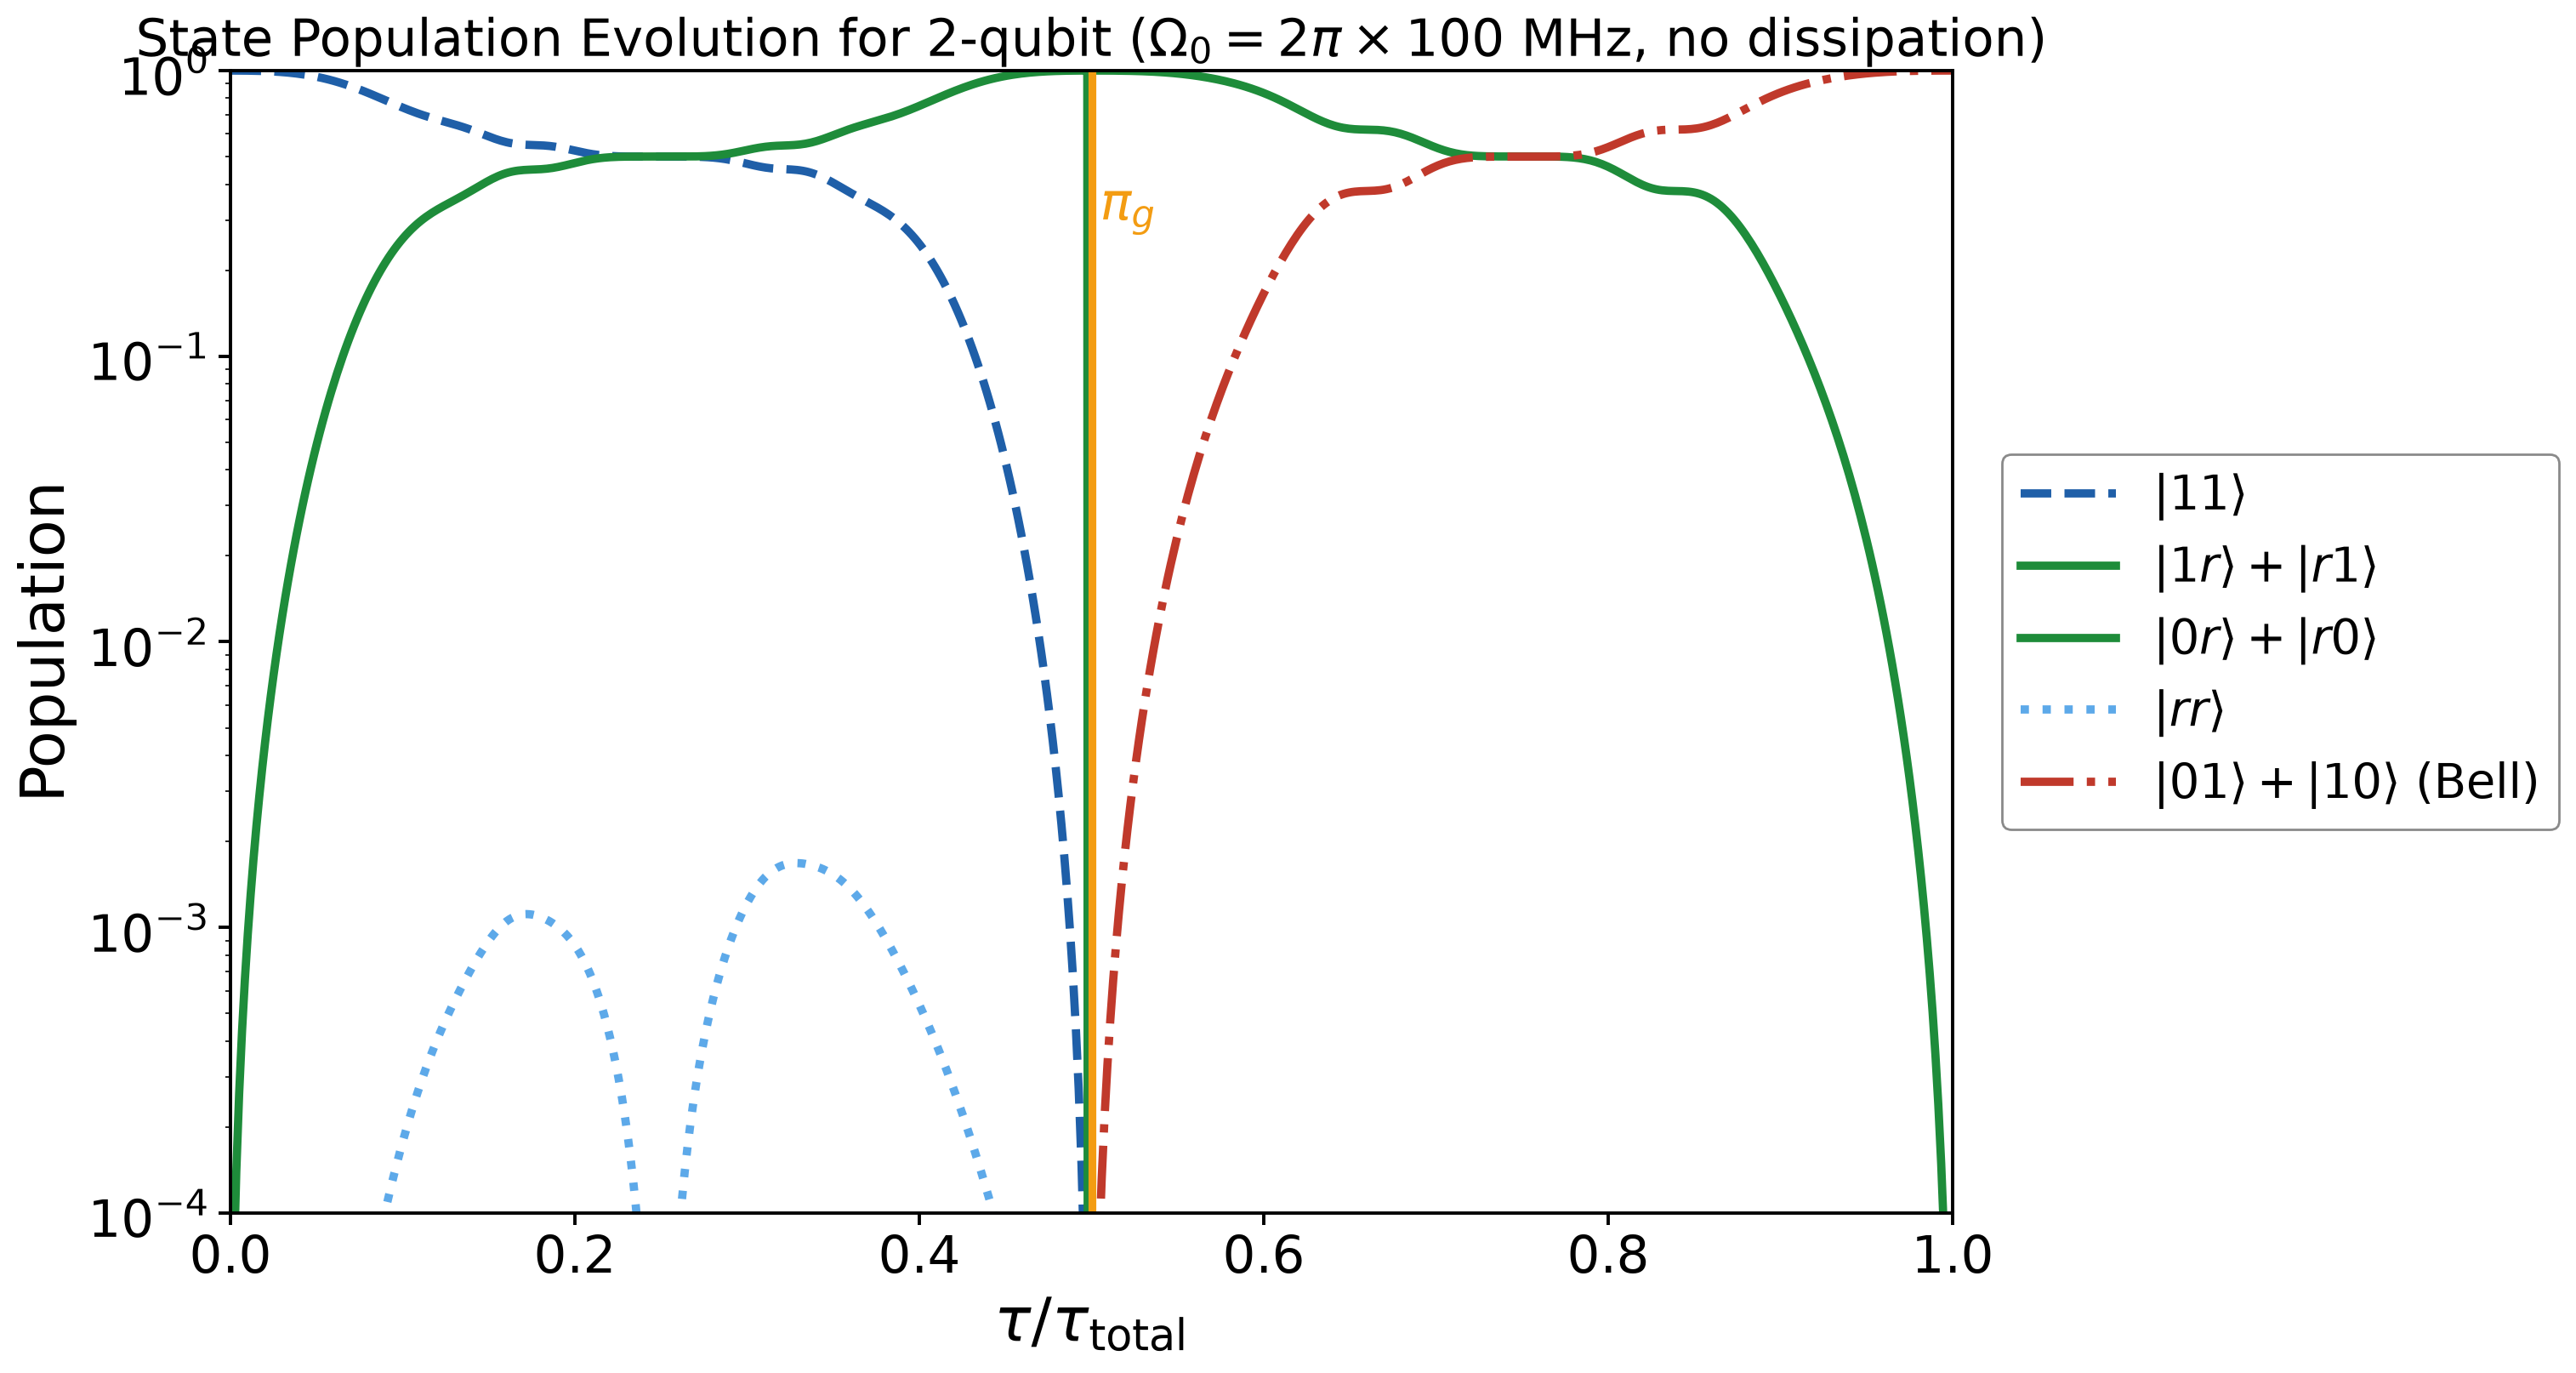


In [ ]:
import numpy as np
from itertools import product
from scipy.linalg import eigh
import matplotlib.pyplot as plt

# ==================== 参数（全部无量纲，Omega0 = 2*pi*100 MHz 为能量/时间单位） ====================
TAU_TOT = 254.64804469273741   # 无量纲总时长
OM1max  = 0.356747            # Omega_max / Omega0
DE1max  = 0.22176485870975582 # Delta_max / Omega0
sR      = 27.050279329608937  # Omega 包络宽度（无量纲）
sD      = 47.3815270018622    # Delta 包络宽度（无量纲）
PF      = 0.501                # pi_g 位置
V0      = 4.319068724444445   # 相互作用 / Omega0
N_step  = 600

# ==================== 全 Hilbert 空间（3 原子，27 维） ====================
st = [''.join(p) for p in product('01r', repeat=3)]
ix = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in ix.items():
    for a in range(3):
        if s[a] == '1':
            s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r':
            s2 = s[:a]+'1'+s[a+1:]
        else:
            continue
        C[ix[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
E_i = np.array([V0*(s.count('r')*(s.count('r')-1)//2) for s in st], float)
g_perm = np.array([ix[s.replace('0','_').replace('1','0').replace('_','1')]
                   for s in st])

# ==================== 演化并记录布居（无耗散） ====================
psi = np.zeros(d, complex)
psi[ix['111']] = 1.0
t_pi = PF*TAU_TOT
dt = TAU_TOT/N_step
n_pi = int(round(PF*N_step))
pops = np.zeros((N_step, d))
for n in range(N_step):
    t = (n+0.5)*dt
    tm = t_pi/2 if t < t_pi else t_pi + (TAU_TOT - t_pi)/2
    xR = (t-tm)/sR
    xD = (t-tm)/sD
    Om = -OM1max*np.sqrt(2*np.e)*xR*np.exp(-xR**2)
    De =  DE1max*np.e*xD**2*np.exp(-xD**2)
    w, v = eigh(Om*C + np.diag(De*n_r + E_i))
    psi = v @ (np.exp(-1j*w*dt)*(v.conj().T @ psi))
    if n == n_pi - 1:                 # t = t_pi 处 pi_g
        psi = psi[g_perm]
    pops[n] = np.abs(psi)**2

F = pops[-1, ix['001']] + pops[-1, ix['010']] + pops[-1, ix['100']]
print("W-state fidelity F =", F)
print("Sum of all pops    =", pops[-1].sum())

# ==================== 画图 ====================
BLUE='#1f5fa8'; GREEN='#1e8c3a'; LBLUE='#5da9e9'; RED='#c0392b'
ORANGE='#f39c12'; PURPLE='#8e44ad'
LW = 3.5
tt = np.linspace(0, 1, N_step)
FS_LAB, FS_TCK, FS_TIT, FS_LEG = 26, 22, 22, 20

fig, ax = plt.subplots(figsize=(15, 8.5))

ax.plot(tt, pops[:, ix['111']], '--', color=BLUE, lw=LW,
        label=r'$|111\rangle$')

ax.plot(tt, pops[:, ix['r11']]+pops[:, ix['1r1']]+pops[:, ix['11r']],
        '-', color=GREEN, lw=LW,
        label=r'$|r11\rangle+|1r1\rangle+|11r\rangle$')

ax.plot(tt, pops[:, ix['r00']]+pops[:, ix['0r0']]+pops[:, ix['00r']],
        '-', color=GREEN, lw=LW,
        label=r'$|r00\rangle+|0r0\rangle+|00r\rangle$')

ax.plot(tt, pops[:, ix['rr1']]+pops[:, ix['r1r']]+pops[:, ix['1rr']],
        ':', color=LBLUE, lw=LW,
        label=r'$|rr1\rangle+|r1r\rangle+|1rr\rangle$')

ax.plot(tt, pops[:, ix['rrr']], '--', color=PURPLE, lw=LW,
        label=r'$|rrr\rangle$')

ax.plot(tt, pops[:, ix['001']]+pops[:, ix['010']]+pops[:, ix['100']],
        '-.', color=RED, lw=LW,
        label=r'$|001\rangle+|010\rangle+|100\rangle$ (W)')

ax.axvline(PF, color=ORANGE, lw=3.3)
ax.text(PF+0.005, 0.3, r'$\pi_g$', color=ORANGE, fontsize=FS_TIT)

ax.set_xlim(0, 1)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)

ax.set_xlabel(r'$\tau/\tau_{\rm total}$', fontsize=FS_LAB)
ax.set_ylabel('Population', fontsize=FS_LAB)
ax.set_title('State Population Evolution for 3-qubit (paper parameters, no dissipation)',
             fontsize=FS_TIT)

ax.legend(fontsize=FS_LEG, loc='center left',
          bbox_to_anchor=(1.015, 0.5),
          framealpha=0.92, edgecolor='gray')

ax.tick_params(axis='both', which='major', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)

plt.subplots_adjust(right=0.80, top=0.90)
plt.savefig('population演化_3比特_无量纲.png', dpi=200, bbox_inches='tight')
plt.show()

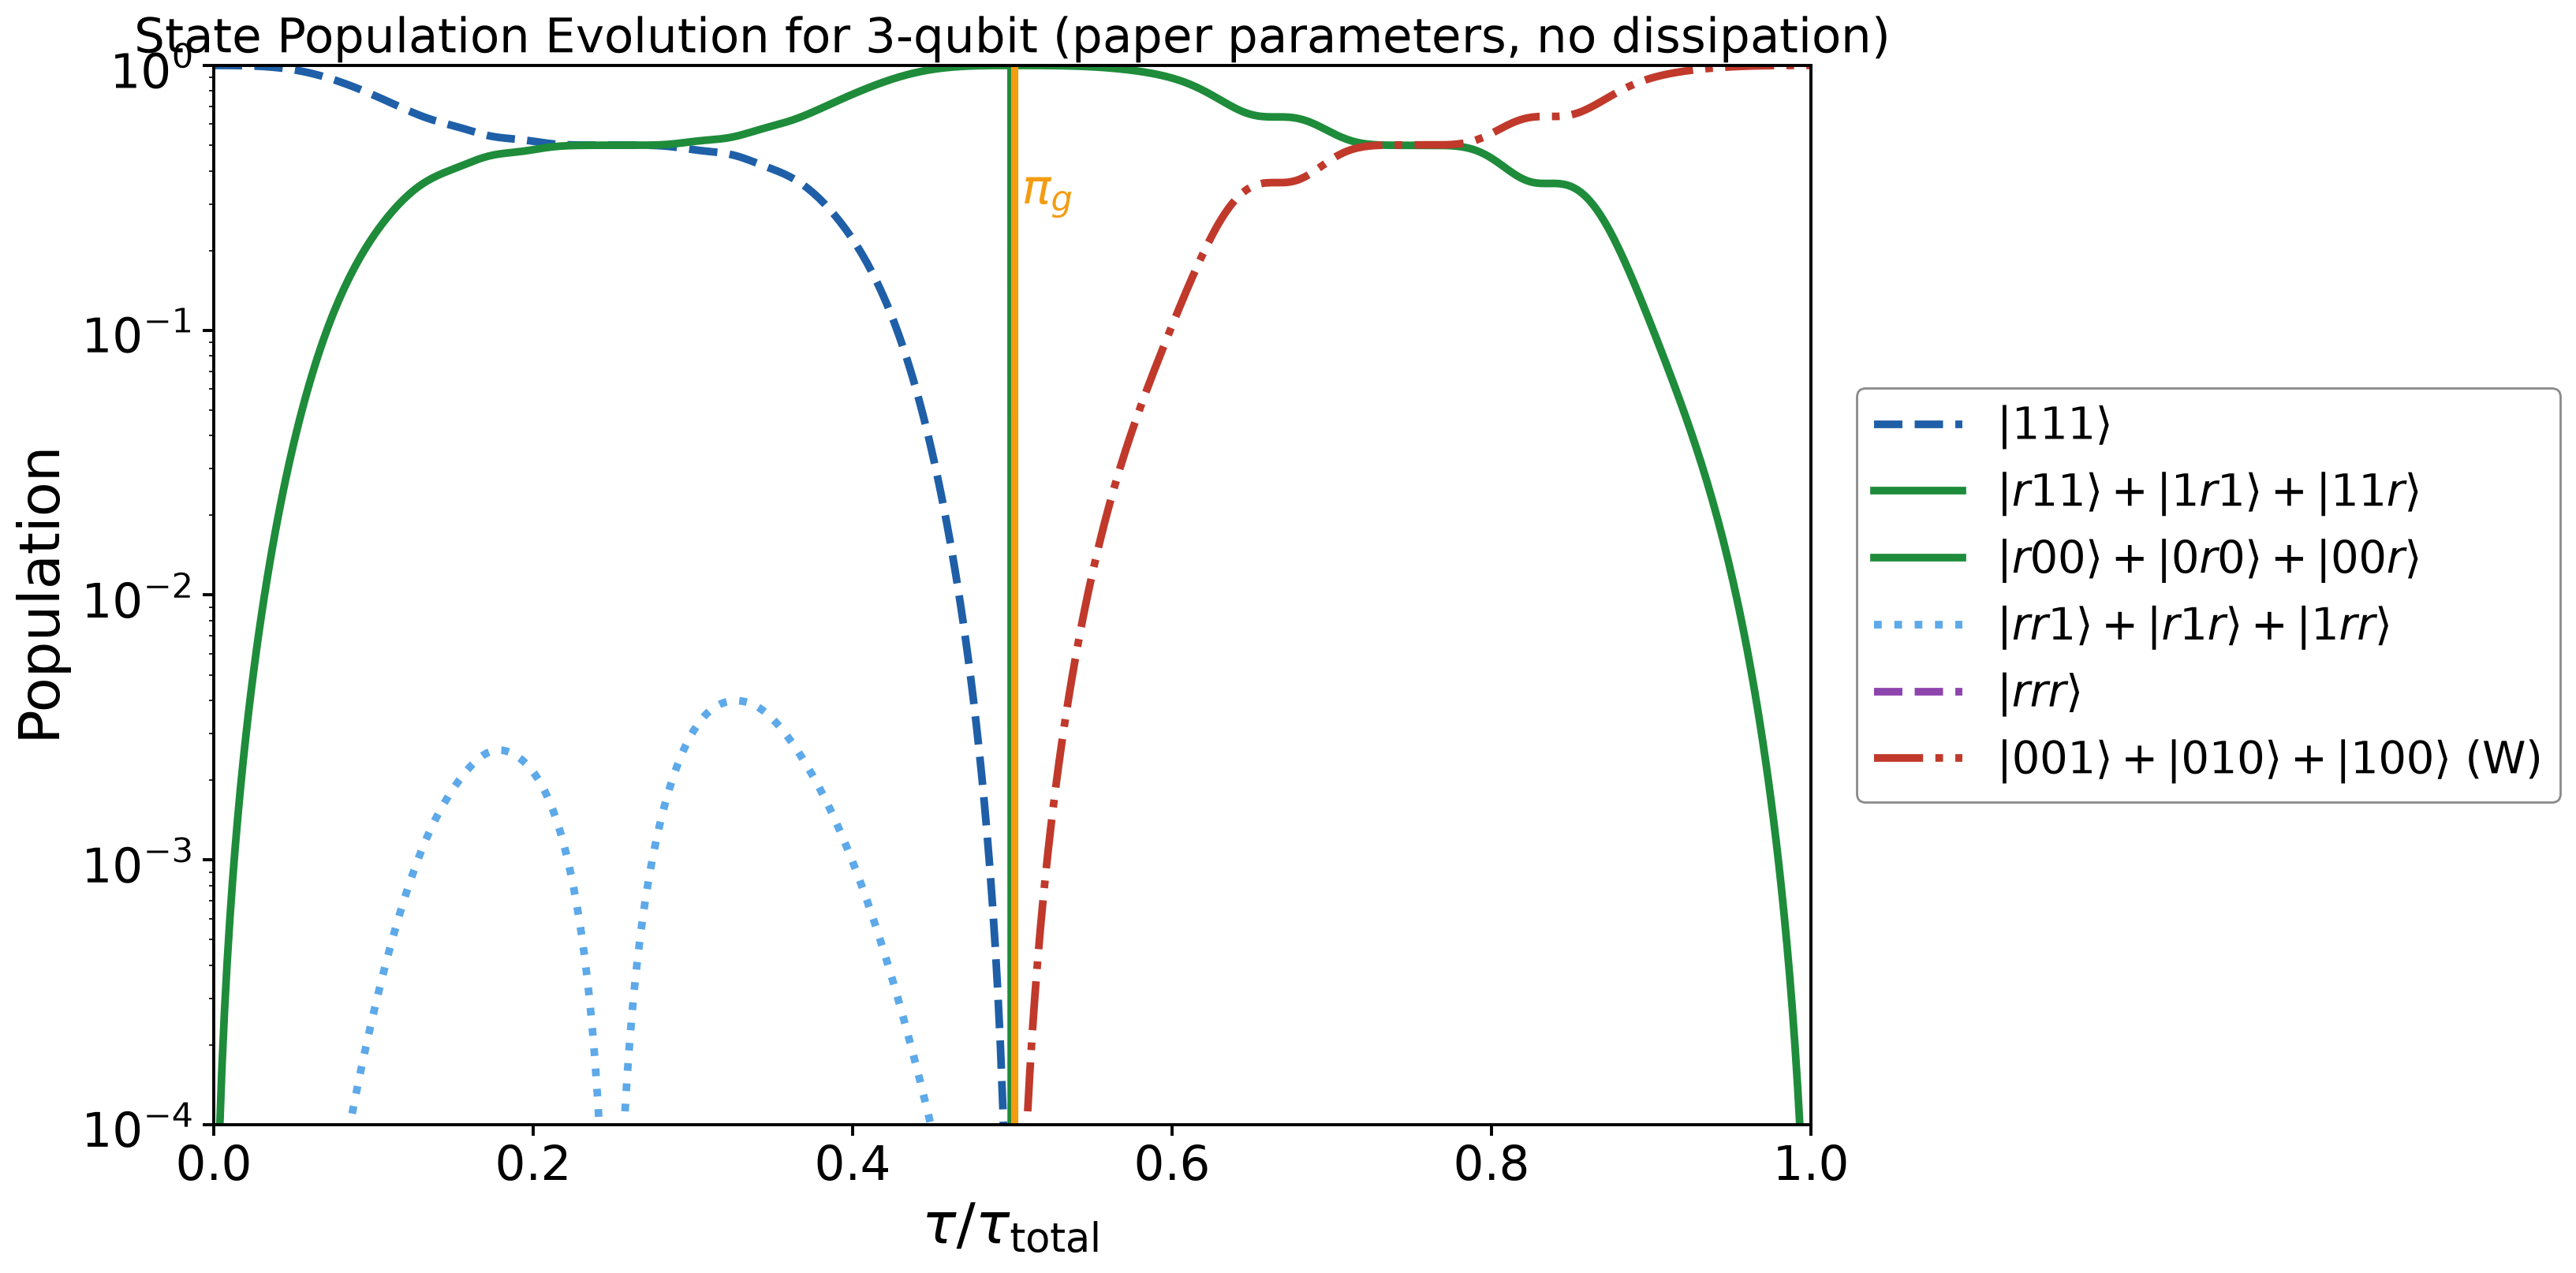
